# QuantCore · 백테스트 리서치

**가상 기업 6개의 합성 일봉 데이터입니다. 실제 주식이나 실제 투자 수익률이 아닙니다.**

Momentum·Mean Reversion·95% Buy & Hold를 같은 종목·기간·체결 규칙으로 비교합니다.
Docker나 API 서버 없이 기존 Python 엔진을 직접 실행합니다. 새로운 외부 데이터 수집·주문은 하지 않습니다.

1. 오른쪽 위 커널에서 **QuantCore (Python 3.12)** 또는 이 프로젝트 `.venv/bin/python`을 선택하세요.
2. **Run All**을 실행하면 표·그래프가 생성됩니다. 저장된 실행 결과도 그대로 볼 수 있습니다.
3. 아래 설정 셀의 종목·전략·비용·평가 봉 수를 바꾸고 이후 셀을 다시 실행할 수 있습니다.
4. 마지막 위젯에서는 종목과 전략을 바꿔 상세 결과를 볼 수 있습니다.

패키지가 없다면 프로젝트 터미널에서 `.venv/bin/python -m pip install -e '.[notebook]' -c requirements.lock`을 실행하세요.


In [1]:
import hashlib
import importlib.util
import json
import os
import sys
from pathlib import Path

if sys.version_info < (3, 12):
    raise RuntimeError('Python 3.12 이상 커널을 선택하세요.')
candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([parent, parent / 'jane' / 'quant'])
REPO_DIR = next((p for p in candidates if (p / 'quantcore/backtesting/engine.py').is_file()), None)
if REPO_DIR is None:
    raise RuntimeError('QuantCore 프로젝트 또는 notebooks 폴더에서 실행하세요.')
required = ['numpy', 'pandas', 'matplotlib', 'IPython', 'ipywidgets', 'sqlalchemy', 'pyarrow', 'jinja2']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    project_python = REPO_DIR / '.venv/bin/python'
    raise RuntimeError(
        f"필요한 패키지가 없습니다: {missing}\n"
        f"현재 커널: {sys.executable}\n"
        f"권장 커널: QuantCore (Python 3.12)\n"
        f"권장 Python 경로: {project_python}\n"
        "오른쪽 위 커널 선택 → 다른 커널 선택 → Python 환경에서 위 경로를 선택하세요.\n"
        "목록에 없으면 프로젝트 터미널에서 make notebook-setup을 실행하고 창을 다시 여세요.\n"
        "커널을 바꾼 후 Restart Kernel → Run All을 실행하세요."
    )
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
os.environ.setdefault('MPLCONFIGDIR', str(REPO_DIR / 'artifacts' / 'matplotlib'))

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import clear_output, display
from matplotlib.ticker import PercentFormatter

import quantcore
from quantcore.backtesting.engine import ExecutionConfig, backtest, simulate
from quantcore.core.models import Bar
from quantcore.data.providers.demo import DemoProvider
from quantcore.research.service import json_safe
from quantcore.strategies.base import STRATEGIES

if Path(quantcore.__file__).resolve().parent != REPO_DIR / 'quantcore':
    raise RuntimeError('다른 quantcore 모듈이 이미 로드되어 있습니다. 커널을 재시작하세요.')
%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})
pd.set_option('display.max_columns', 24)
print('Project:', REPO_DIR)
print('Python:', sys.executable)
print('Data: SYNTHETIC / USD / research only')


Project: /Users/kanghyeon/Desktop/Project/jane/quant
Python: /Users/kanghyeon/Desktop/Project/jane/quant/.venv/bin/python
Data: SYNTHETIC / USD / research only


## 1. 비교 조건

기본값은 README와 같습니다. 2023-01-02부터 780개 가상 평일 중 마지막 **252봉(2025-01-09~12-26)**을 평가합니다.
수익률은 전체 평가 기간의 누적값입니다. `SYMBOL`은 `QALPHA`, `QBETA`, `QGAMMA`, `QDELTA`, `QEPSILON`, `QZETA` 중 선택합니다.

- Momentum: 종가가 60봉 평균보다 높으면 목표 비중 95%.
- Mean Reversion: 20봉 z-score < −1에서 진입, ≥0에서 청산.
- Buy & Hold: 목표 비중 95%를 유지하는 재조정 벤치마크.
- 이전 종가로 만든 신호를 **다음 봉 시가**에 체결합니다. 이전 봉 거래량의 1%까지만 체결합니다.
- 편도 수수료 1bp, 슬리피지 2bp, 전체 spread 2bp(편도 절반), 참여율 기반 영향 5bp×√참여율.
- 정수 수량·Decimal 현금 원장, 공매도·차입·펀딩 없음. 마지막 미청산 포지션은 종가 평가합니다.


In [2]:
SYMBOL = 'QALPHA'
STRATEGY = 'momentum'  # momentum / mean_reversion / buy_hold
CONFIG = ExecutionConfig(
    initial_cash=100_000,
    evaluation_bars=252,
    commission_bps=1,
    slippage_bps=2,
    spread_bps=2,
    impact_bps=5,
    max_participation=.01,
)
EXPORT_RESULTS = True  # 로컬 artifacts/notebook_backtest/에 CSV·JSON·PNG 저장
display(pd.Series(CONFIG.model_dump(), name='assumption').to_frame())


,assumption
initial_cash,100000.00
commission_bps,1.00
slippage_bps,2.00
spread_bps,2.00
impact_bps,5.00
max_participation,0.01
max_weight,1.00
evaluation_bars,252.00


## 2. 데이터와 출처 확인

로컬 `datasets/prices.parquet`가 있으면 해시와 스키마를 확인해 읽습니다. 없으면 기존 `DemoProvider(seed=20261124)`로 동일한 합성 자료를 메모리에 생성합니다.
기존 DB·원본 파일은 수정하지 않습니다. `available_at` 이후의 정보만 사용할 수 있다는 데이터 계약을 확인합니다.


In [3]:
price_path = REPO_DIR / 'datasets/prices.parquet'
manifest_path = REPO_DIR / 'datasets/manifest.json'
if price_path.exists():
    input_hash = hashlib.sha256(price_path.read_bytes()).hexdigest()
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
        if manifest['sha256'] != input_hash:
            raise RuntimeError('가격 파일 해시가 manifest와 다릅니다. 입력을 확인하세요.')
    market = pd.read_parquet(price_path)
    input_origin = 'local Parquet (read only)'
else:
    provider = DemoProvider()
    batches = [await provider.fetch(asset.symbol) for asset in provider.assets()]
    market = pd.DataFrame([bar.model_dump() for batch in batches for bar in batch])
    input_hash = hashlib.sha256(pd.util.hash_pandas_object(market, index=True).values.tobytes()).hexdigest()
    input_origin = 'in-memory seeded DemoProvider'
market['timestamp'] = pd.to_datetime(market.timestamp, utc=True)
market['available_at'] = pd.to_datetime(market.available_at, utc=True)
if set(market['mode']) != {'synthetic'} or set(market.source) != {'quantcore-synthetic-v1'}:
    raise RuntimeError('현재 노트북은 QuantCore 합성 데모 데이터용입니다. 실제 자료로 잘못 표시하지 않습니다.')
for record in market.to_dict('records'):
    Bar.model_validate(record)
if market.duplicated(['symbol', 'timestamp']).any():
    raise RuntimeError('종목별 중복 봉이 있습니다.')
FRAMES = {symbol: group.set_index('timestamp').sort_index() for symbol, group in market.groupby('symbol')}
if SYMBOL not in FRAMES or STRATEGY not in STRATEGIES:
    raise ValueError('SYMBOL 또는 STRATEGY 설정이 올바르지 않습니다.')
display(market.groupby('symbol').agg(rows=('close', 'size'), start=('timestamp', 'min'), end=('timestamp', 'max')))
print('Origin:', input_origin)
print('Input SHA-256:', input_hash)
print('Source:', market.source.iloc[0], '| Currency: USD | Mode: synthetic')


,rows,start,end
symbol,,,
QALPHA,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00
QBETA,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00
QDELTA,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00
QEPSILON,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00
QGAMMA,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00
QZETA,780,2023-01-02 21:00:00+00:00,2025-12-26 21:00:00+00:00


Origin: local Parquet (read only)
Input SHA-256: 65982c3e823485f747d4e75fe403246392eb7f7c7d9f7f9cd8f7c489c0ef9ea2
Source: quantcore-synthetic-v1 | Currency: USD | Mode: synthetic


## 3. 6개 종목 · 두 전략 · 벤치마크 비교
각 종목을 별도로 시뮬레이션합니다. 종목 수익률을 합산한 포트폴리오 성과가 아닙니다.


,symbol,strategy,total_return,gross_total_return,benchmark_total_return,sharpe,max_drawdown,fills,total_cost
0,QALPHA,momentum,7.35%,8.24%,35.11%,0.562,-15.37%,150,$865.66
1,QALPHA,mean_reversion,9.55%,10.29%,35.11%,1.293,-4.09%,38,$720.02
2,QALPHA,buy_hold,35.11%,35.17%,35.11%,1.927,-6.64%,169,$44.46
3,QBETA,momentum,-12.60%,-11.71%,-4.75%,-0.849,-15.12%,82,$947.62
4,QBETA,mean_reversion,9.62%,10.77%,-4.75%,0.870,-11.05%,70,"$1,195.19"
5,QBETA,buy_hold,-4.75%,-4.71%,-4.75%,-0.169,-18.76%,125,$44.29
6,QDELTA,momentum,-5.07%,-4.39%,-21.89%,-0.271,-15.66%,43,$702.19
7,QDELTA,mean_reversion,-10.10%,-9.51%,-21.89%,-0.647,-18.16%,61,$696.76
8,QDELTA,buy_hold,-21.89%,-21.83%,-21.89%,-0.996,-34.45%,79,$44.11
9,QEPSILON,momentum,7.19%,7.55%,-7.31%,0.442,-15.92%,90,$350.33


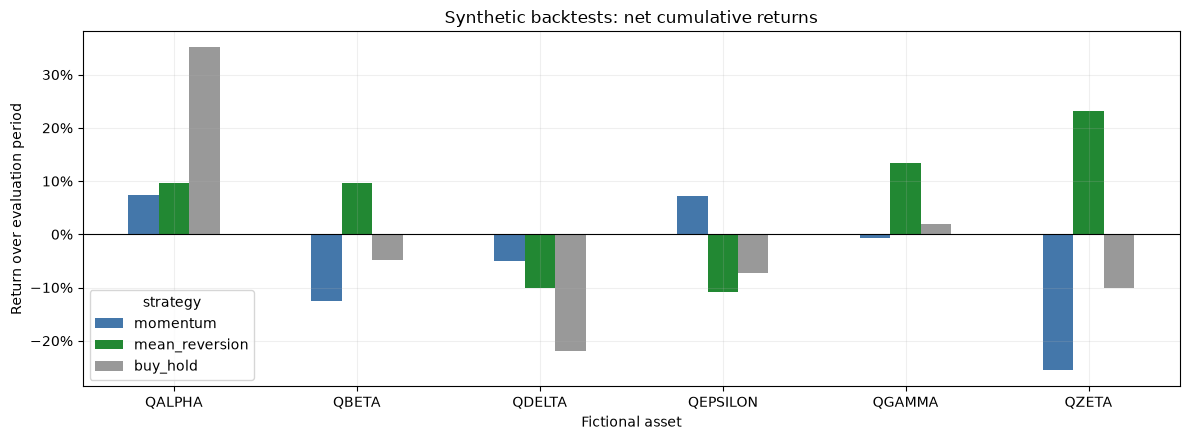

In [4]:
RESULTS = {}
summary_rows = []
for symbol, frame in FRAMES.items():
    for name in ('momentum', 'mean_reversion', 'buy_hold'):
        result = backtest(frame, STRATEGIES[name](), CONFIG)
        RESULTS[symbol, name] = result
        summary_rows.append({'symbol': symbol, 'strategy': name, **result['metrics'],
                             'gross_total_return': result['gross_metrics']['total_return'],
                             'benchmark_total_return': result['benchmark_metrics']['total_return']})
SUMMARY = pd.DataFrame(summary_rows)
return_columns = ['total_return', 'gross_total_return', 'benchmark_total_return', 'max_drawdown', 'win_rate']
formats = {column: '{:.2%}' for column in return_columns}
formats.update(sharpe='{:.3f}', total_cost='${:,.2f}', turnover='{:.3f}')
display(SUMMARY[['symbol', 'strategy', 'total_return', 'gross_total_return', 'benchmark_total_return',
                 'sharpe', 'max_drawdown', 'fills', 'total_cost']].style.format(formats, na_rep='—'))
NET = SUMMARY.pivot(index='symbol', columns='strategy', values='total_return')
ax = NET[['momentum', 'mean_reversion', 'buy_hold']].plot.bar(color=['#4477aa', '#228833', '#999999'])
ax.axhline(0, color='black', linewidth=.8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Synthetic backtests: net cumulative returns', ylabel='Return over evaluation period', xlabel='Fictional asset')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. 선택 종목의 수익곡선과 낙폭

실선은 비용 차감 후, 점선은 비용을 0으로 놓고 다시 실행한 결과입니다. **비용 전 성과는 실제 투자 성과 추정치가 아닙니다.**
평가 시작 직전의 초기 자금을 곡선에 포함해 첫날부터의 손실과 낙폭을 표시합니다.


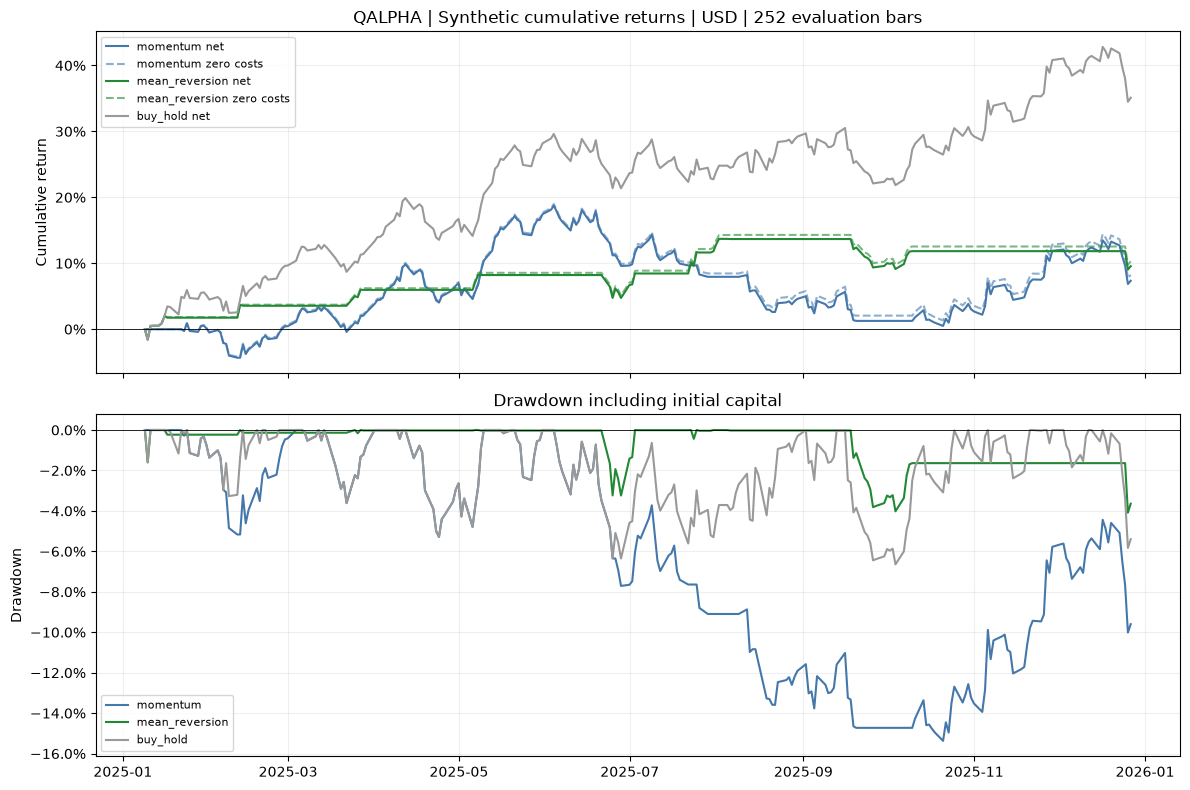

In [5]:
def equity_frame(symbol, result):
    curve = pd.DataFrame(result['curve'])
    curve['timestamp'] = pd.to_datetime(curve.timestamp, utc=True)
    curve = curve.set_index('timestamp')
    frame = FRAMES[symbol]
    initial_at = frame.index[frame.index.get_loc(curve.index[0]) - 1]
    initial = pd.DataFrame({'equity': [CONFIG.initial_cash], 'benchmark_equity': [CONFIG.initial_cash]},
                           index=pd.DatetimeIndex([initial_at], name='timestamp'))
    return pd.concat([initial, curve]).sort_index()

COLORS = {'momentum': '#4477aa', 'mean_reversion': '#228833', 'buy_hold': '#999999'}
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ZERO_COST = CONFIG.model_copy(update=dict(commission_bps=0, slippage_bps=0, spread_bps=0, impact_bps=0))
for name, color in COLORS.items():
    result = RESULTS[SYMBOL, name]
    curve = equity_frame(SYMBOL, result)
    net = curve.equity / CONFIG.initial_cash - 1
    axes[0].plot(curve.index, net, label=name+' net', color=color)
    drawdown = curve.equity / curve.equity.cummax() - 1
    axes[1].plot(curve.index, drawdown, label=name, color=color)
    assert np.isclose(drawdown.min(), result['metrics']['max_drawdown'], atol=1e-12)
    if name != 'buy_hold':
        gross_result = simulate(FRAMES[SYMBOL], STRATEGIES[name](), ZERO_COST)
        gross_curve = equity_frame(SYMBOL, gross_result)
        axes[0].plot(gross_curve.index, gross_curve.equity / CONFIG.initial_cash - 1,
                     linestyle='--', alpha=.6, color=color, label=name+' zero costs')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.axhline(0, color='black', linewidth=.6)
    ax.legend(loc='best', fontsize=8)
axes[0].set(title=f'{SYMBOL} | Synthetic cumulative returns | USD | {CONFIG.evaluation_bars} evaluation bars', ylabel='Cumulative return')
axes[1].set(title='Drawdown including initial capital', ylabel='Drawdown')
plt.tight_layout()
plt.show()


## 5. 상세 지표 · 매수/매도 위치 · 체결 내역

승률과 Profit Factor는 **청산 매도 체결** 기준이며 완전한 왕복 거래 단위와 다를 수 있습니다.
매수/매도 표시는 실제 모의 체결 시각과 가격입니다. 이전 종가의 신호 시각과 다음 시가의 체결 시각을 표에서 함께 확인합니다.


QALPHA / momentum | SYNTHETIC / USD | 2025-01-09 → 2025-12-26


,value
metric,
total_return,7.35%
cagr,7.35%
annualized_volatility,14.49%
sharpe,0.562
sortino,0.810
max_drawdown,-15.37%
drawdown_duration_bars,148
calmar,0.478
fills,150


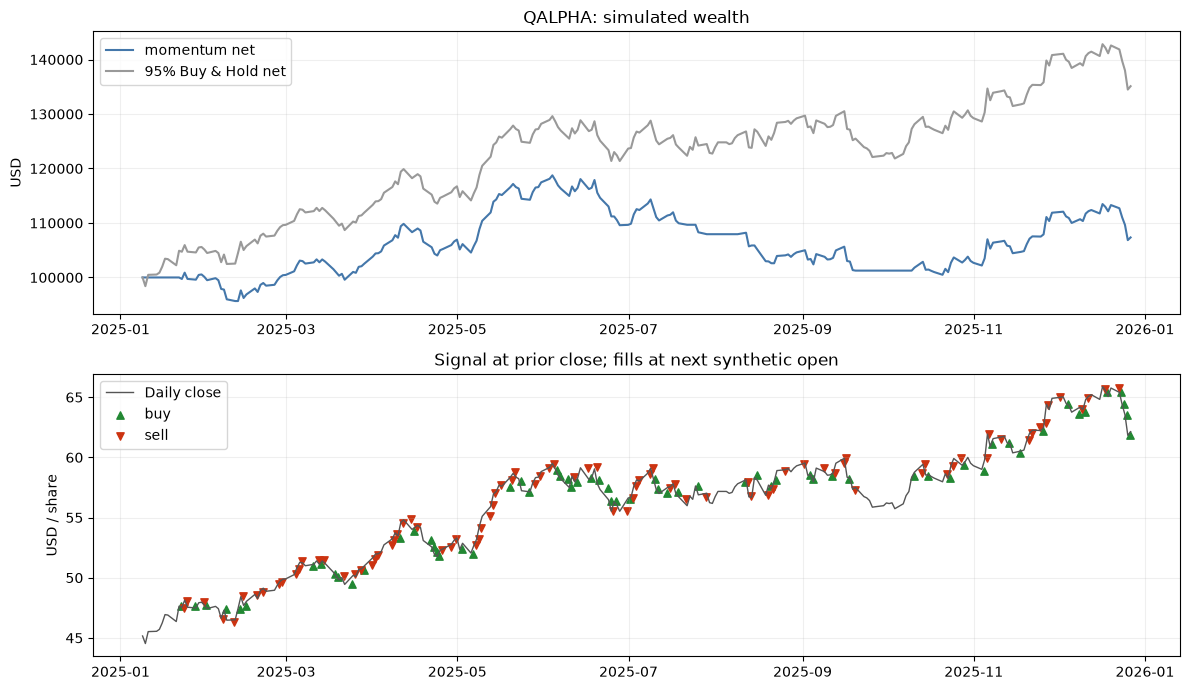

,signal_at,timestamp,side,quantity,price,commission,total_cost,cash_after,inventory_after,partial_fill,realized_pnl
125,2025-11-04T21:00:00+00:00,2025-11-05T14:30:00+00:00,sell,1,59.931370,0.0060,0.024001,5189.8580,1644,False,1.486838
126,2025-11-05T21:00:00+00:00,2025-11-06T14:30:00+00:00,sell,3,61.960396,0.0186,0.074491,5375.7206,1641,False,10.546914
127,2025-11-06T21:00:00+00:00,2025-11-07T14:30:00+00:00,buy,1,61.078720,0.0061,0.024432,5314.6358,1642,False,0.000000
128,2025-11-07T21:00:00+00:00,2025-11-10T14:30:00+00:00,sell,1,61.502620,0.0062,0.024698,5376.1322,1641,False,3.056226
129,2025-11-12T21:00:00+00:00,2025-11-13T14:30:00+00:00,buy,1,61.209937,0.0061,0.024493,5314.9162,1642,False,0.000000
130,2025-11-14T21:00:00+00:00,2025-11-17T14:30:00+00:00,buy,1,60.366932,0.0060,0.024137,5254.5433,1643,False,0.000000
131,2025-11-19T21:00:00+00:00,2025-11-20T14:30:00+00:00,sell,1,61.435544,0.0061,0.024559,5315.9727,1642,False,2.986361
132,2025-11-20T21:00:00+00:00,2025-11-21T14:30:00+00:00,sell,1,62.066003,0.0062,0.024856,5378.0325,1641,False,3.616761
133,2025-11-21T21:00:00+00:00,2025-11-24T14:30:00+00:00,sell,1,62.494736,0.0062,0.024972,5440.5210,1640,False,4.045461
134,2025-11-24T21:00:00+00:00,2025-11-25T14:30:00+00:00,buy,1,62.226340,0.0062,0.024884,5378.2885,1641,False,0.000000


In [6]:
def show_detail(symbol, name):
    result = RESULTS[symbol, name]
    print(f'{symbol} / {name} | SYNTHETIC / USD | {result["period"]["start"][:10]} → {result["period"]["end"][:10]}')
    percent_metrics = {'total_return', 'cagr', 'annualized_volatility', 'max_drawdown', 'win_rate',
                       'alpha', 'tracking_error', 'benchmark_relative_return'}
    metric_rows = []
    for key, value in result['metrics'].items():
        if value is None:
            formatted = '—'
        elif key in percent_metrics:
            formatted = f'{value:.2%}'
        elif key == 'total_cost':
            formatted = f'${value:,.2f}'
        elif key in {'fills', 'closed_fills', 'drawdown_duration_bars'}:
            formatted = str(int(value))
        else:
            formatted = f'{value:,.3f}'
        metric_rows.append({'metric': key, 'value': formatted})
    display(pd.DataFrame(metric_rows).set_index('metric'))
    curve = equity_frame(symbol, result)
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    axes[0].plot(curve.index, curve.equity, label=name+' net', color=COLORS[name])
    axes[0].plot(curve.index, curve.benchmark_equity, label='95% Buy & Hold net', color='#999999')
    axes[0].set(title=f'{symbol}: simulated wealth', ylabel='USD')
    axes[0].legend()
    price = FRAMES[symbol].loc[curve.index.min():, 'close']
    axes[1].plot(price.index, price, label='Daily close', color='#555555', linewidth=1)
    fills = pd.DataFrame(result['fills'])
    if not fills.empty:
        for side, marker, color in [('buy', '^', '#228833'), ('sell', 'v', '#cc3311')]:
            chosen = fills[fills.side == side]
            axes[1].scatter(pd.to_datetime(chosen.timestamp, utc=True), chosen.price,
                            marker=marker, color=color, label=side, s=28)
        assert (pd.to_datetime(fills.signal_at, utc=True) < pd.to_datetime(fills.timestamp, utc=True)).all()
    axes[1].set(title='Signal at prior close; fills at next synthetic open', ylabel='USD / share')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    if fills.empty:
        print('이 조건에서는 체결이 없습니다.')
    else:
        display(fills[['signal_at', 'timestamp', 'side', 'quantity', 'price', 'commission', 'total_cost',
                       'cash_after', 'inventory_after', 'partial_fill', 'realized_pnl']].tail(25))
    return result

SELECTED = show_detail(SYMBOL, STRATEGY)


## 6. 월별 수익률 · 비용 민감도

월별 수익률은 일별 수익률의 복리입니다. 비용 민감도는 수수료·슬리피지·spread·impact 계수를 함께 배수 적용해 재실행합니다.
계수 변경에 따라 보유 수량과 체결이 바뀔 수 있으므로 결과 차이를 비용 항목의 단순 합으로 해석하지 않습니다.


,equity,benchmark_equity
timestamp,,
2025-01,-0.50%,4.49%
2025-02,0.97%,4.95%
2025-03,3.34%,3.34%
2025-04,3.01%,3.00%
2025-05,9.83%,9.83%
2025-06,-6.64%,-3.54%
2025-07,-1.56%,0.20%
2025-08,-3.09%,4.28%
2025-09,-3.20%,-4.94%


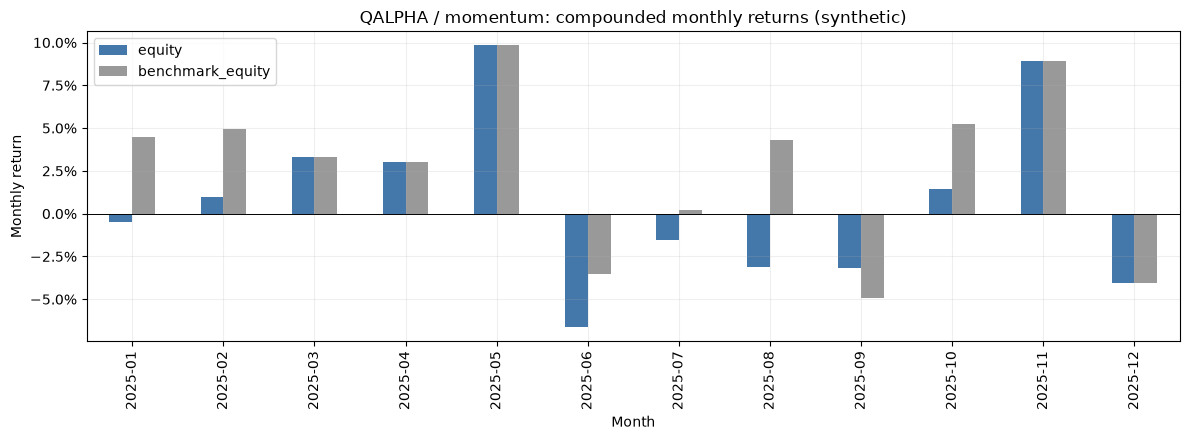

,cost_multiplier,total_return,max_drawdown,total_cost,fills
0,0.000000,8.24%,-14.84%,$0.00,146
1,0.500000,7.79%,-15.10%,$433.72,152
2,1.000000,7.35%,-15.37%,$865.66,150
3,2.000000,6.46%,-15.90%,"$1,724.50",149


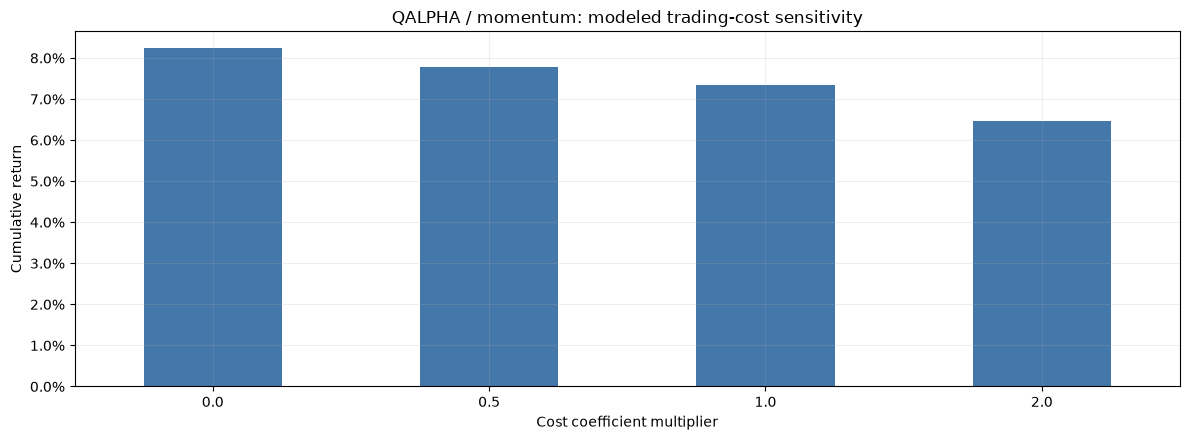

In [7]:
selected_curve = equity_frame(SYMBOL, SELECTED)
daily = selected_curve[['equity', 'benchmark_equity']].pct_change().iloc[1:]
monthly = (1 + daily).resample('MS').prod() - 1
monthly.index = monthly.index.strftime('%Y-%m')
display(monthly.style.format('{:.2%}'))
ax = monthly.plot.bar(color=[COLORS[STRATEGY], '#999999'])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title=f'{SYMBOL} / {STRATEGY}: compounded monthly returns (synthetic)', ylabel='Monthly return', xlabel='Month')
ax.axhline(0, color='black', linewidth=.7)
plt.tight_layout()
plt.show()

cost_rows = []
for multiplier in (0., .5, 1., 2.):
    scaled = CONFIG.model_copy(update={name: getattr(CONFIG, name)*multiplier for name in
                                      ('commission_bps', 'slippage_bps', 'spread_bps', 'impact_bps')})
    result = simulate(FRAMES[SYMBOL], STRATEGIES[STRATEGY](), scaled)
    cost_rows.append({'cost_multiplier': multiplier, **result['metrics']})
COST_SENSITIVITY = pd.DataFrame(cost_rows)
display(COST_SENSITIVITY[['cost_multiplier', 'total_return', 'max_drawdown', 'total_cost', 'fills']]
        .style.format({'total_return': '{:.2%}', 'max_drawdown': '{:.2%}', 'total_cost': '${:,.2f}'}))
ax = COST_SENSITIVITY.plot.bar(x='cost_multiplier', y='total_return', legend=False, color='#4477aa')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title=f'{SYMBOL} / {STRATEGY}: modeled trading-cost sensitivity', ylabel='Cumulative return', xlabel='Cost coefficient multiplier')
ax.axhline(0, color='black', linewidth=.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. 저장 결과 대조 · 결과 내보내기

기본 설정이고 입력 해시가 일치하면 README의 저장 실험과 12개 전략 수익률을 대조합니다.
설정이나 입력이 다르면 동일 실험이라고 표시하지 않습니다. CSV/JSON은 `artifacts/notebook_backtest/`에 저장하며 Git에서 제외됩니다.


In [8]:
reference_path = REPO_DIR / 'docs/research_results.json'
reference_status = 'not compared: input/config differs or saved report absent'
if reference_path.exists():
    reference = json.loads(reference_path.read_text())
    if CONFIG.model_dump() == ExecutionConfig().model_dump() and input_hash == reference['dataset']['sha256']:
        deltas = []
        for saved in reference['strategy_results']:
            actual = RESULTS[saved['symbol'], saved['strategy']]['metrics']['total_return']
            deltas.append(abs(actual - saved['total_return']))
        assert len(deltas) == 12 and max(deltas) < 1e-10
        reference_status = f'matched 12 saved strategy results; max return difference={max(deltas):.3e}'
print('Reference:', reference_status)
if EXPORT_RESULTS:
    engine_hash = hashlib.sha256((REPO_DIR / 'quantcore/backtesting/engine.py').read_bytes()
                                + (REPO_DIR / 'quantcore/strategies/base.py').read_bytes()).hexdigest()
    run_id = hashlib.sha256(json.dumps({'config': CONFIG.model_dump(), 'input': input_hash, 'engine': engine_hash}, sort_keys=True).encode()).hexdigest()[:12]
    OUTPUT_DIR = REPO_DIR / 'artifacts/notebook_backtest' / run_id
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    SUMMARY.to_csv(OUTPUT_DIR / 'metrics.csv', index=False)
    COST_SENSITIVITY.to_csv(OUTPUT_DIR / 'cost_sensitivity.csv', index=False)
    monthly.to_csv(OUTPUT_DIR / 'selected_monthly_returns.csv')
    curve_exports, fill_exports = [], []
    for (symbol, name), result in RESULTS.items():
        curve_exports.append(pd.DataFrame(result['curve']).assign(symbol=symbol, strategy=name))
        if result['fills']:
            fill_exports.append(pd.DataFrame(result['fills']).assign(symbol=symbol, strategy=name))
    pd.concat(curve_exports, ignore_index=True).to_csv(OUTPUT_DIR / 'curves.csv', index=False)
    if fill_exports:
        pd.concat(fill_exports, ignore_index=True).to_csv(OUTPUT_DIR / 'fills.csv', index=False)
    metadata = {'mode': 'synthetic', 'source': 'quantcore-synthetic-v1', 'input_origin': input_origin,
                'input_sha256': input_hash, 'engine_sha256': engine_hash, 'config': CONFIG.model_dump(),
                'selected_symbol': SYMBOL, 'selected_strategy': STRATEGY, 'reference_check': reference_status,
                'result_count': len(RESULTS), 'note': 'Fictional demo; not actual market performance'}
    (OUTPUT_DIR / 'experiment.json').write_text(json.dumps(json_safe(metadata), indent=2)+chr(10))
    print('CSV / JSON:', OUTPUT_DIR)


Reference: matched 12 saved strategy results; max return difference=0.000e+00
CSV / JSON: /Users/kanghyeon/Desktop/Project/jane/quant/artifacts/notebook_backtest/945f8918270b


## 8. 선택해서 보기

종목·전략을 선택하고 **상세 결과 보기**를 누르면 아래 출력이 갱신됩니다.
위젯이 표시되지 않는 환경에서는 위 설정 셀의 `SYMBOL`, `STRATEGY`를 바꾸고 이후 셀을 실행하세요.

현재 결과로 실전 수익성·실제 거래소 체결·실제 역사적 위기 대응을 검증했다고 판단할 수 없습니다.
추가 가정은 `docs/backtesting_methodology.md`, 전체 수치는 `docs/research_results.json`을 참조하세요.


In [9]:
asset_picker = widgets.Dropdown(options=sorted(FRAMES), value=SYMBOL, description='종목:')
strategy_picker = widgets.Dropdown(options=list(STRATEGIES), value=STRATEGY, description='전략:')
detail_button = widgets.Button(description='상세 결과 보기', button_style='info')
detail_output = widgets.Output()

def refresh_detail(_):
    with detail_output:
        clear_output(wait=True)
        show_detail(asset_picker.value, strategy_picker.value)

detail_button.on_click(refresh_detail)
display(widgets.HBox([asset_picker, strategy_picker, detail_button]), detail_output)


Output()